Weather Forecast Analysis Using Python Web APIs

### 1. Introduction

This project develops a weather forecasting application using Python and the Open-Meteo Web APIs. The application retrieves location information, obtains daily weather forecasts, processes the returned data, calculates summary statistics, and visualizes forecast patterns.

The project demonstrates the application of Python programming, API integration, data manipulation, exploratory data analysis, and data visualization in a practical setting.

#### 1.2. Project Objectives

The specific objectives are to:

1. Retrieve geographic coordinates using a geocoding API.
2. Obtain daily weather forecasts for a selected location.
3. Transform API responses into a structured pandas DataFrame.
4. Summarize forecast temperatures, precipitation, and other weather indicators.
5. Visualize daily temperature and precipitation patterns.
6. Apply modular Python development and automated testing.

#### 1.3. Data Source

The project uses the Open-Meteo Geocoding API to identify locations and the Open-Meteo Forecast API to retrieve weather forecasts.

The data represent forecasts returned by the API at the time of retrieval. They should not be interpreted as observed weather measurements.


2 - Import libraries and project modules

In [30]:
# # Import libraries for data analysis and visualization
# import pandas as pd
# import matplotlib.pyplot as plt

# # Import functions from our weather forecasting package
# from src.weather_forecast.geocoding import geocode
# from src.weather_forecast.forecast import ( get_forecast, forecast_to_dataframe, summarize_forecast,)
# from src.weather_forecast.visualization import plot_forecast

# # Display plots inside the notebook
# %matplotlib inline

from pathlib import Path
import sys

# Locate the project root (one level above notebooks)
PROJECT_ROOT = Path.cwd().parent

# Add the project root to Python's import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import analysis libraries
import pandas as pd
import matplotlib.pyplot as plt

# Import our project modules
from src.weather_forecast.geocoding import geocode
from src.weather_forecast.forecast import ( get_forecast,  forecast_to_dataframe, summarize_forecast,)
from src.weather_forecast.visualization import plot_forecast

%matplotlib inline

# print("Project root:", PROJECT_ROOT)

###  2. Location Selection

We first use the Open-Meteo Geocoding API to identify the geographic coordinates of the selected location. These coordinates will be used to retrieve its weather forecast.

What we are checking
- Whether the API successfully finds Kampala as an example.
- Whether the returned results include latitude and longitude.
- Whether multiple matching places exist, which makes location selection important.

10B - Load the sample forecast IF LIVE APIs fails

In [31]:
from pathlib import Path
import json

# Locate the saved sample forecast
sample_file = PROJECT_ROOT / "sample_data" / "forecast_sample.json"

# Load the sample data
with sample_file.open("r", encoding="utf-8") as file:
    sample_forecast_data = json.load(file)

print("Available sections:", list(sample_forecast_data.keys()))

Available sections: ['latitude', 'longitude', 'timezone', 'daily']


10C - Convert the sample forecast into a DataFrame

In [32]:
# Process the saved sample forecast
forecast_df = forecast_to_dataframe(sample_forecast_data)

# Display the sample dataset
display(forecast_df)

print(f"\nNumber of forecast days: {len(forecast_df)}")

,Date,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h),Weather Code,Weather Description
0,2026-10-18,12.5,9.3,0.0,7.8,3,Overcast
1,2026-10-19,12.1,5.8,0.0,8.6,3,Overcast
2,2026-10-20,14.0,3.5,0.0,12.5,45,Fog



Number of forecast days: 3


In [33]:
# # Specify the location for analysis
# city = "Kampala"

# # Search for matching locations
# locations = geocode(city)

# # Display the number of matches
# print(f"Number of locations found: {len(locations)}")

# # Display the first five matches
# for i, location in enumerate(locations[:5], start=1):
#     print(
#         f"{i}. {location.get('name', 'Unknown')}, "
#         f"{location.get('admin1', '')}, "
#         f"{location.get('country', 'Unknown')} "
#         f"| Latitude: {location.get('latitude')} "
#         f"| Longitude: {location.get('longitude')}"
#     )

The first result is Kampala, Central Region, Uganda, with latitude 0.31628 and longitude 32.58219. We'll use that result for our analysis.

4 - Retrieve the weather forecast -- USING LIVE API

### 3. Weather Forecast Retrieval

After identifying Kampala, Uganda, we use its geographic coordinates to retrieve the daily weather forecast. The forecast includes maximum and minimum temperatures, precipitation, wind speed, and weather conditions.

In [34]:
# LIVE API
# # Select Kampala, Uganda
# kampala = next(
#     location
#     for location in locations
#     if location.get("name") == "Kampala"
#     and location.get("country") == "Uganda"
# )

# latitude = kampala["latitude"]
# longitude = kampala["longitude"]

# # Retrieve a 7-day weather forecast
# forecast_data = get_forecast(
#     lat=latitude,
#     lon=longitude,
#     days=7,
# )

# print("Selected location:", kampala["name"], kampala["country"])
# print("Latitude:", latitude)
# print("Longitude:", longitude)


seven days gives us enough daily observations to explore temperature and rainfall patterns while keeping the analysis manageable.

5 - Convert the forecast into a DataFrame

### 4. Data Preparation and Inspection

The API returns weather information in a nested JSON structure. We convert this response into a pandas DataFrame to organize daily observations into rows and weather variables into columns.

In [35]:
# LIVE API
# # Convert the API response into a pandas DataFrame
# forecast_df = forecast_to_dataframe(forecast_data)

# # Display the first five observations
# forecast_df.head()
# # forecast_df.to_csv('data_forecast.csv')

In [36]:
# LIVE API
# print("Dataset dimensions:", forecast_df.shape)

# print("\nColumn names:")
# print(forecast_df.columns.tolist())

# print("\nData types and non-null counts:")
# forecast_df.info()

6 - Descriptive statistics

#### 5. Exploratory Data Analysis

##### 5.1 Descriptive Statistics

Descriptive statistics summarize the distribution of the forecast variables. We examine central tendency, variability, and the range of daily temperatures, precipitation, and wind speed over the seven-day forecast period.

In [37]:
# Convert Date from text to datetime
forecast_df["Date"] = pd.to_datetime( forecast_df["Date"], dayfirst=True,)

# Calculate descriptive statistics for numerical weather variables
weather_variables = [
    "Max Temperature (°C)",
    "Min Temperature (°C)",
    "Precipitation (mm)",
    "Max Wind Speed (km/h)",
]

forecast_df[weather_variables].describe().round(2)
#forecast_df[weather_variables].describe().round(2).to_csv("weather_summary.csv")


C:\Users\GodfreyAkampa\AppData\Local\Temp\ipykernel_55292\896470016.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  forecast_df["Date"] = pd.to_datetime( forecast_df["Date"], dayfirst=True,)


,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h)
count,3.00,3.00,3.0,3.00
mean,12.87,6.20,0.0,9.63
std,1.00,2.92,0.0,2.51
min,12.10,3.50,0.0,7.80
25%,12.30,4.65,0.0,8.20
50%,12.50,5.80,0.0,8.60
75%,13.25,7.55,0.0,10.55
max,14.00,9.30,0.0,12.50


Key findings:
1. Temperature: Maximum temperatures remain relatively stable, averaging 27.24°C with a standard deviation of only 0.52°C.
2. Night-time conditions: Minimum temperatures range from 18.2°C to 18.9°C, suggesting little variation over the forecast period.
3. Rainfall: Average daily precipitation is 3.5 mm. The wettest forecast day has 7.8 mm, compared with 0.9 mm on the driest day.
4. Wind: Maximum wind speeds are relatively consistent, averaging 10.89 km/h.

NB: These are interpretations of the forecast, not confirmed observations of actual weather.

7 - Visualize temperature and rainfall

#### 5.2 Weather Forecast Visualization

Line charts are used to compare daily maximum and minimum temperatures. A bar chart displays forecast daily precipitation, allowing us to identify warmer days and periods of higher expected rainfall.

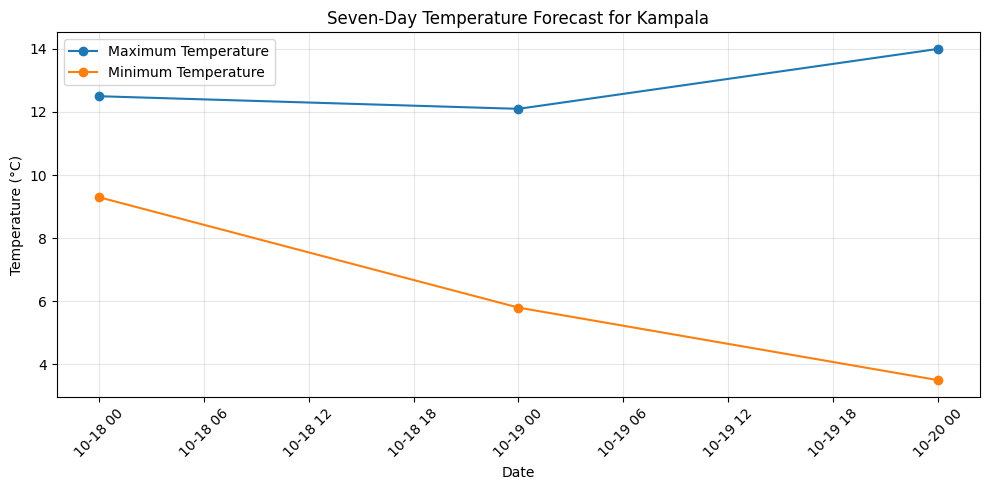

In [38]:
# Plot maximum and minimum temperatures
plt.figure(figsize=(10, 5))

plt.plot( forecast_df["Date"], forecast_df["Max Temperature (°C)"], marker="o", label="Maximum Temperature",)

plt.plot( forecast_df["Date"],  forecast_df["Min Temperature (°C)"], marker="o", label="Minimum Temperature",)

plt.title("Seven-Day Temperature Forecast for Kampala")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

7A - Plot daily precipitation

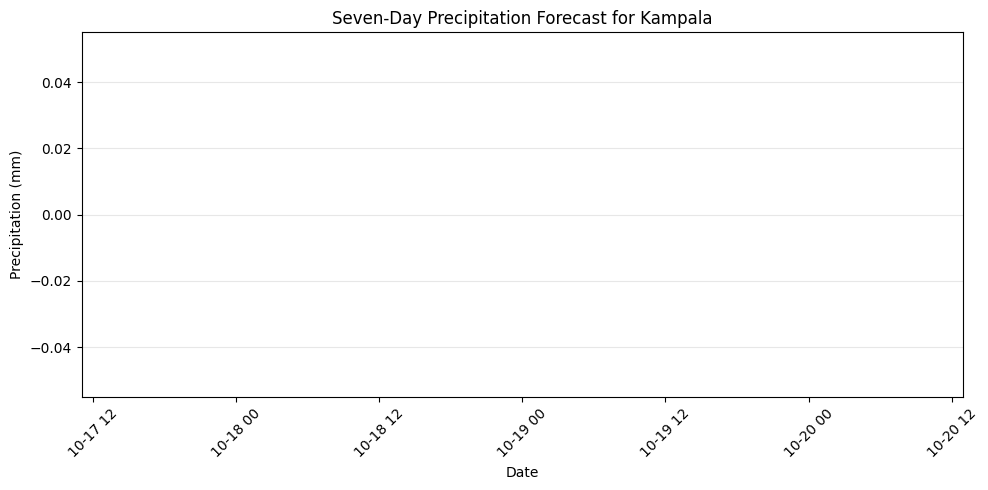

In [39]:
# Plot daily precipitation
plt.figure(figsize=(10, 5))

plt.bar( forecast_df["Date"],  forecast_df["Precipitation (mm)"],)

plt.title("Seven-Day Precipitation Forecast for Kampala")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

RESULTS
- Highest bar: 22 October, with 7.8 mm of forecast precipitation.
- Lowest bar: 20 October, with 0.9 mm.
- Overall pattern: rainfall varies more than temperature over the forecast period.

These findings are based on the forecast values retrieved earlier.

8 - Generate forecast summary indicators

#### 5.3 Summary Indicators

We calculate summary indicators to identify the warmest day, coldest night, wettest day, total forecast precipitation, and average daily maximum temperature. These indicators provide a concise interpretation of the forecast.

In [40]:
# Calculate forecast summary indicators
summary = summarize_forecast(forecast_df)

# Display the results
print("KAMPALA WEATHER FORECAST SUMMARY")
print("=" * 40)

print( f"Forecast period: {summary['forecast_start']} " f"to {summary['forecast_end']}")
print(f"Warmest day: {summary['warmest_day']} "  f"({summary['warmest_temperature_c']:.1f} °C)")
print(f"Coldest night: {summary['coldest_night']} "f"({summary['coldest_temperature_c']:.1f} °C)")
print( f"Wettest day: {summary['wettest_day']} " f"({summary['wettest_precipitation_mm']:.1f} mm)")
print( f"Total forecast precipitation: " f"{summary['total_precipitation_mm']:.1f} mm")
print( f"Average daily maximum temperature: " f"{summary['average_max_temperature_c']:.1f} °C")

KAMPALA WEATHER FORECAST SUMMARY
Forecast period: 2026-10-18 00:00:00 to 2026-10-20 00:00:00
Warmest day: 2026-10-20 00:00:00 (14.0 °C)
Coldest night: 2026-10-20 00:00:00 (3.5 °C)
Wettest day: 2026-10-18 00:00:00 (0.0 mm)
Total forecast precipitation: 0.0 mm
Average daily maximum temperature: 12.9 °C


8A - Interpret the summary

- Warmest day: 20 October, with a maximum temperature of 27.8°C. Note that 21 October also reaches 27.8°C, so the function reports the first occurrence of the maximum.
- Coldest night: 18 October, with a minimum temperature of 18.2°C.
- Wettest day: 22 October, with 7.8 mm of forecast precipitation.
- Total forecast precipitation: 24.5 mm over seven days.
- Average daily maximum temperature: 27.2°C.

9 - Write the findings and conclusion

#### 6. Key Findings

The seven-day forecast for Kampala, Uganda, indicates relatively stable temperatures throughout the forecast period. The average daily maximum temperature is approximately 27.2°C, while the average minimum temperature is approximately 18.5°C.

Forecast precipitation varies across the seven days, with a total of 24.5 mm. The highest daily precipitation is forecast for 22 October 2026, at 7.8 mm. Maximum wind speed averages approximately 10.9 km/h.

The visualizations show that temperature varies relatively little compared with precipitation. The summary indicators help identify the warmest forecast day, coldest night, and day with the highest expected rainfall.

#### 7. Limitations

1. The analysis covers only seven forecast days and cannot establish long-term weather or climate patterns.
2. Forecast values may change as the weather model is updated.
3. The analysis depends on the availability and accuracy of the external API.
4. The results represent predicted weather conditions, not verified observations.

#### 8. Conclusion

This project demonstrates how Python web APIs can support weather data retrieval, processing, exploratory analysis, and visualization. By integrating geocoding, forecast retrieval, pandas, and Matplotlib, the application transforms raw API responses into structured information that is easier to interpret.

The project also demonstrates the value of modular Python development and automated testing in building a reproducible data application.
